In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("C:/Users/Admin/Desktop/SQL_Projects/project_sql/3_job_on_demand.csv")

print(df.head())
print(df.info())
print(df.describe())

     skills  demand_count
0       sql         92470
1     excel         66901
2    python         57238
3   tableau         46469
4  power bi         39419
<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   skills        10 non-null     str  
 1   demand_count  10 non-null     int64
dtypes: int64(1), str(1)
memory usage: 342.0 bytes
None
       demand_count
count      10.00000
mean    39925.90000
std     26386.81799
min     11289.00000
25%     17372.50000
50%     34728.50000
75%     54545.75000
max     92470.00000


In [2]:
# Remove duplicate skill names
df = df.drop_duplicates(subset="skills")

# Remove missing values
df = df.dropna(subset=["skills", "demand_count"])

# Convert demand count to numeric
df["demand_count"] = pd.to_numeric(
    df["demand_count"],
    errors="coerce"
)

df = df.dropna(subset=["demand_count"])

# Sort by demand
df = df.sort_values(
    by="demand_count",
    ascending=False
)

# Calculate share of top-10 skill mentions
df["demand_percentage"] = (
    df["demand_count"] / df["demand_count"].sum() * 100
)

print(df)

       skills  demand_count  demand_percentage
0         sql         92470          23.160405
1       excel         66901          16.756291
2      python         57238          14.336058
3     tableau         46469          11.638811
4    power bi         39419           9.873040
5           r         30038           7.523437
6         sas         28042           7.023511
7  powerpoint         13816           3.460410
8        word         13577           3.400550
9         sap         11289           2.827488


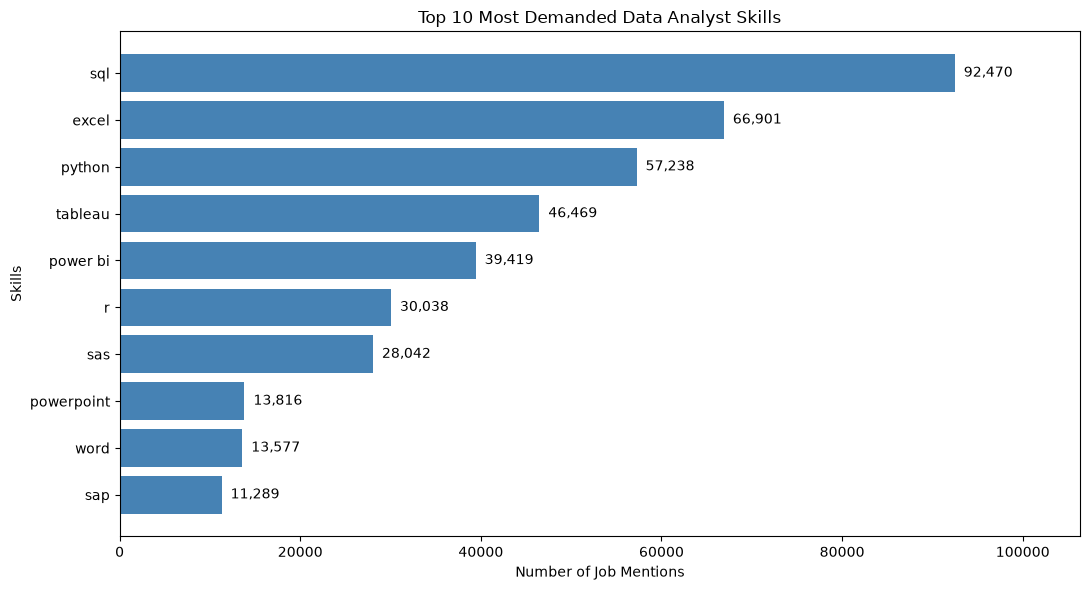

In [3]:
top_skills = df.nlargest(10, "demand_count")

plt.figure(figsize=(11, 6))

plt.barh(
    top_skills["skills"],
    top_skills["demand_count"],
    color="steelblue"
)

plt.gca().invert_yaxis()

plt.title("Top 10 Most Demanded Data Analyst Skills")
plt.xlabel("Number of Job Mentions")
plt.ylabel("Skills")

for i, value in enumerate(top_skills["demand_count"]):
    plt.text(value + 1000, i, f"{value:,}", va="center")

plt.xlim(0, top_skills["demand_count"].max() * 1.15)
plt.tight_layout()
plt.show()